In [1]:
# import record into student list array to use
import csv

student_list = []
with open("records.csv", newline="", encoding="utf-8") as file:
    reader = csv.DictReader(file)
    for row in reader:
        student = {
            "tutorial": row["Tutorial Group"].strip(),
            "student_id": row["Student ID"].strip(),
            "name": row["Name"].strip(),
            "school": row["School"].strip(),
            "gender": row["Gender"].strip(),
            "cgpa": float(row["CGPA"]),
        }
        student_list.append(student)

In [2]:
tutorial_grp = {}

for student in student_list:
    tutorial = student["tutorial"]
    if tutorial not in tutorial_grp:
        tutorial_grp[tutorial] = []
    tutorial_grp[tutorial].append(student)

# sort student based on tutorial group

In [3]:
# settle GPA first for each group
# we can get upper band and lower band students based on using 33rd and 67th percentile
# the func below helps to calculate the threshold for each tutorial group
def calculate_performance_thresholds(cgpa_list):
    """Find the cutoff points to divide students into Low/Medium/High groups"""
    sorted_cgpas = sorted(cgpa_list)
    total_students = len(sorted_cgpas)

    if total_students == 0:
        return (0, 0)

    # Find 33rd and 67th percentile positions
    low_cutoff = sorted_cgpas[total_students // 3]
    high_cutoff = sorted_cgpas[2 * total_students // 3]

    return (low_cutoff, high_cutoff)


tutorial_grp_threshold = {}

for tutorial, students in tutorial_grp.items():
    cgpa_list = [student["cgpa"] for student in students]
    low_threshold, high_threshold = calculate_performance_thresholds(cgpa_list)
    tutorial_grp_threshold[tutorial] = {"cgpa": (low_threshold, high_threshold)}
print(tutorial_grp_threshold)

# part 1 of getting the standard deviation is done, now we need to get the average gende

{'G-1': {'cgpa': (4.04, 4.12)}, 'G-10': {'cgpa': (4.06, 4.17)}, 'G-100': {'cgpa': (4.05, 4.14)}, 'G-101': {'cgpa': (4.05, 4.15)}, 'G-102': {'cgpa': (4.05, 4.14)}, 'G-103': {'cgpa': (4.07, 4.15)}, 'G-104': {'cgpa': (4.03, 4.11)}, 'G-105': {'cgpa': (4.05, 4.15)}, 'G-106': {'cgpa': (4.02, 4.14)}, 'G-107': {'cgpa': (4.02, 4.12)}, 'G-108': {'cgpa': (4.02, 4.11)}, 'G-109': {'cgpa': (4.02, 4.15)}, 'G-11': {'cgpa': (4.02, 4.14)}, 'G-110': {'cgpa': (4.03, 4.11)}, 'G-111': {'cgpa': (4.03, 4.15)}, 'G-112': {'cgpa': (4.06, 4.15)}, 'G-113': {'cgpa': (4.03, 4.11)}, 'G-114': {'cgpa': (4.03, 4.12)}, 'G-115': {'cgpa': (4.05, 4.15)}, 'G-116': {'cgpa': (4.04, 4.14)}, 'G-117': {'cgpa': (4.05, 4.17)}, 'G-118': {'cgpa': (4.04, 4.15)}, 'G-119': {'cgpa': (4.06, 4.15)}, 'G-12': {'cgpa': (4.05, 4.19)}, 'G-120': {'cgpa': (4.04, 4.14)}, 'G-13': {'cgpa': (4.0, 4.12)}, 'G-14': {'cgpa': (4.03, 4.14)}, 'G-15': {'cgpa': (4.01, 4.12)}, 'G-16': {'cgpa': (4.03, 4.12)}, 'G-17': {'cgpa': (4.05, 4.12)}, 'G-18': {'cgpa': (4.

In [4]:
# now lets tackle the gender distribution for each tutorial group
# we can get a count of both genders in each tutorial group
# then we can compare the ratio of each gender in each tutorial group
# based on the numbers, and the input for x to form a team,
# we can form a team with balanced gender distribution


def calculate_gender_ratio(students):
    """Calculate the ratio of male to female students"""
    total = len(students)
    if total == 0:
        return 0.0

    male_count = sum(1 for s in students if s["gender"] == "Male")
    female_count = total - male_count

    return male_count / female_count if female_count > 0 else float("inf")


for tutorial, students in tutorial_grp.items():
    gender_ratio = calculate_gender_ratio(students)
    tutorial_grp_threshold[tutorial]["gender_ratio"] = gender_ratio
    # print(f"Tutorial {tutorial}: Gender Ratio = {gender_ratio:.2f}")

print(tutorial_grp_threshold)
# now, the ratio means if >1, it means more males than females
# if <1, it means more females than males
# if =1, it means equal number of males and females

{'G-1': {'cgpa': (4.04, 4.12), 'gender_ratio': 0.7241379310344828}, 'G-10': {'cgpa': (4.06, 4.17), 'gender_ratio': 1.0833333333333333}, 'G-100': {'cgpa': (4.05, 4.14), 'gender_ratio': 0.7857142857142857}, 'G-101': {'cgpa': (4.05, 4.15), 'gender_ratio': 1.0}, 'G-102': {'cgpa': (4.05, 4.14), 'gender_ratio': 0.7857142857142857}, 'G-103': {'cgpa': (4.07, 4.15), 'gender_ratio': 1.0}, 'G-104': {'cgpa': (4.03, 4.11), 'gender_ratio': 0.6666666666666666}, 'G-105': {'cgpa': (4.05, 4.15), 'gender_ratio': 0.9230769230769231}, 'G-106': {'cgpa': (4.02, 4.14), 'gender_ratio': 0.9230769230769231}, 'G-107': {'cgpa': (4.02, 4.12), 'gender_ratio': 0.6129032258064516}, 'G-108': {'cgpa': (4.02, 4.11), 'gender_ratio': 1.0}, 'G-109': {'cgpa': (4.02, 4.15), 'gender_ratio': 0.6666666666666666}, 'G-11': {'cgpa': (4.02, 4.14), 'gender_ratio': 0.8518518518518519}, 'G-110': {'cgpa': (4.03, 4.11), 'gender_ratio': 0.6666666666666666}, 'G-111': {'cgpa': (4.03, 4.15), 'gender_ratio': 1.173913043478261}, 'G-112': {'cgp

In [5]:
# count unique schools in tutorial group
# sets only store unique values
def count_unique_schools(students):
    """Count unique schools in tutorial group"""
    schools = set()
    for student in students:
        schools.add(student["school"])
    return len(schools)


# add school diversity to existing threshold data
for tutorial, students in tutorial_grp.items():
    unique_schools = count_unique_schools(students)
    tutorial_grp_threshold[tutorial]["school_diversity"] = unique_schools

print(tutorial_grp_threshold)

{'G-1': {'cgpa': (4.04, 4.12), 'gender_ratio': 0.7241379310344828, 'school_diversity': 15}, 'G-10': {'cgpa': (4.06, 4.17), 'gender_ratio': 1.0833333333333333, 'school_diversity': 17}, 'G-100': {'cgpa': (4.05, 4.14), 'gender_ratio': 0.7857142857142857, 'school_diversity': 17}, 'G-101': {'cgpa': (4.05, 4.15), 'gender_ratio': 1.0, 'school_diversity': 15}, 'G-102': {'cgpa': (4.05, 4.14), 'gender_ratio': 0.7857142857142857, 'school_diversity': 15}, 'G-103': {'cgpa': (4.07, 4.15), 'gender_ratio': 1.0, 'school_diversity': 16}, 'G-104': {'cgpa': (4.03, 4.11), 'gender_ratio': 0.6666666666666666, 'school_diversity': 14}, 'G-105': {'cgpa': (4.05, 4.15), 'gender_ratio': 0.9230769230769231, 'school_diversity': 16}, 'G-106': {'cgpa': (4.02, 4.14), 'gender_ratio': 0.9230769230769231, 'school_diversity': 13}, 'G-107': {'cgpa': (4.02, 4.12), 'gender_ratio': 0.6129032258064516, 'school_diversity': 14}, 'G-108': {'cgpa': (4.02, 4.11), 'gender_ratio': 1.0, 'school_diversity': 15}, 'G-109': {'cgpa': (4.02,

In [6]:
# now with 3 medians or whatever you call it, we can create a func to assign performance level


def create_balanced_groups(tutorial_id, students, group_size=5):
    """
    Create balanced groups based on tutorial_grp_threshold data

    Args:
        tutorial_id (str): Tutorial ID (e.g., 'G-1')
        students (list): List of student dictionaries
        group_size (int): Number of students per group

    Returns:
        list: List of groups, each group is a list of students
    """

    # get threshold data for this tutorial
    # unlikely to happen, but its an edge case we want to handle
    if tutorial_id not in tutorial_grp_threshold:
        print(f"Warning: No threshold data found for {tutorial_id}")
        return simple_group_split(students, group_size)

    # retrieve data from threshold
    thresholds = tutorial_grp_threshold[tutorial_id]
    cgpa_low, cgpa_high = thresholds["cgpa"]
    target_gender_ratio = thresholds["gender_ratio"]

    # categorize students by performance
    high_performers = []
    mid_performers = []
    low_performers = []

    for student in students:
        cgpa = student["cgpa"]
        if cgpa >= cgpa_high:
            high_performers.append(student)
        elif cgpa <= cgpa_low:
            low_performers.append(student)
        else:
            mid_performers.append(student)

    # separate by gender
    males = [s for s in students if s["gender"] == "M"]
    females = [s for s in students if s["gender"] == "F"]

    # calculate number of groups
    num_groups = len(students) // group_size
    groups = [[] for _ in range(num_groups)]

    # distribute high performers first (1 per group if possible)
    distribute_evenly(high_performers, groups, group_size)

    # distribute low performers (1 per group if possible)
    distribute_evenly(low_performers, groups, group_size)

    # fill remaining spots with mid performers
    distribute_evenly(mid_performers, groups, group_size)

    # balance gender within each group
    balance_gender_in_groups(groups, males, females, target_gender_ratio)

    # balance schools within each group
    balance_schools_in_groups(groups)

    # fill any remaining spots
    remaining_students = get_remaining_students(students, groups)
    distribute_remaining(remaining_students, groups, group_size)

    return groups


def distribute_evenly(student_list, groups, group_size=5):
    """Distribute students evenly across groups, respecting group size limit"""
    for student in student_list:
        # find the group with the least students that isn't full
        best_group = None
        min_size = float("inf")

        for group in groups:
            if len(group) < group_size and len(group) < min_size:
                min_size = len(group)
                best_group = group

        if best_group is not None:
            best_group.append(student)


def balance_gender_in_groups(groups, males, females, target_ratio):
    """Try to balance gender in each group based on target ratio"""
    for group in groups:
        current_males = len([s for s in group if s["gender"] == "Male"])
        current_females = len([s for s in group if s["gender"] == "Female"])

        if current_females == 0:
            current_ratio = float("inf")
        else:
            current_ratio = current_males / current_females

        # ff current ratio is too high (too many males), try to add females
        if current_ratio > target_ratio and females:
            for female in females:
                if not is_student_in_groups(female, groups):
                    group.append(female)
                    break
        # ff current ratio is too low (too many females), try to add males
        elif current_ratio < target_ratio and males:
            for male in males:
                if not is_student_in_groups(male, groups):
                    group.append(male)
                    break
        # ensure no group is completely single-gender
        elif current_males == 0 and females:
            for female in females:
                if not is_student_in_groups(female, groups):
                    group.append(female)
                    break
        elif current_females == 0 and males:
            for male in males:
                if not is_student_in_groups(male, groups):
                    group.append(male)
                    break


def balance_schools_in_groups(groups):
    """Try to maximize school diversity within each group"""
    for group in groups:
        schools_in_group = set()
        for student in group:
            schools_in_group.add(student["school"])
        # school balancing logic would go here
        # for now, we just track diversity


def is_student_in_groups(student, groups):
    """Check if student is already assigned to any group"""
    for group in groups:
        if student in group:
            return True
    return False


def get_remaining_students(all_students, groups):
    """Get students not yet assigned to any group"""
    assigned_students = set()
    for group in groups:
        for student in group:
            assigned_students.add(id(student))

    remaining = []
    for student in all_students:
        if id(student) not in assigned_students:
            remaining.append(student)

    return remaining


def distribute_remaining(remaining_students, groups, group_size):
    """Distribute remaining students to groups that aren't full"""
    for student in remaining_students:
        for group in groups:
            if len(group) < group_size:
                group.append(student)
                break


def simple_group_split(students, group_size):
    """Simple fallback grouping if no threshold data available"""
    groups = []
    for i in range(0, len(students), group_size):
        group = students[i : i + group_size]
        groups.append(group)
    return groups

In [7]:
# loop for the func to run for each tutorial group

for group, students in tutorial_grp.items():
    fk = create_balanced_groups(group, students, 5)
    print(fk)

[[{'tutorial': 'G-1', 'student_id': '2091', 'name': 'Adlan Bin Rahman', 'school': 'EEE', 'gender': 'Male', 'cgpa': 4.2}, {'tutorial': 'G-1', 'student_id': '659', 'name': 'Maria Ivanovna', 'school': 'SSS', 'gender': 'Female', 'cgpa': 4.2}, {'tutorial': 'G-1', 'student_id': '4563', 'name': 'Anjali Patel', 'school': 'WKW SCI', 'gender': 'Female', 'cgpa': 4.01}, {'tutorial': 'G-1', 'student_id': '1555', 'name': 'Prerna Gupta', 'school': 'MAE', 'gender': 'Female', 'cgpa': 4.04}, {'tutorial': 'G-1', 'student_id': '4520', 'name': 'Henry Foster', 'school': 'EEE', 'gender': 'Male', 'cgpa': 4.11}], [{'tutorial': 'G-1', 'student_id': '5708', 'name': 'Ananya Ramesh', 'school': 'SoH', 'gender': 'Male', 'cgpa': 4.2}, {'tutorial': 'G-1', 'student_id': '4820', 'name': 'Meera Singh', 'school': 'CoE', 'gender': 'Female', 'cgpa': 4.22}, {'tutorial': 'G-1', 'student_id': '2115', 'name': 'Anya Kumar', 'school': 'EEE', 'gender': 'Female', 'cgpa': 4.03}, {'tutorial': 'G-1', 'student_id': '75', 'name': 'Sakin

In [8]:
import csv


def save_team_formations_to_csv(tutorial_groups, filename="team_formations.csv"):
    """Save all team formations to a CSV file with required columns"""

    # Prepare data for CSV
    csv_data = []

    # Process each tutorial group
    for tutorial_id in tutorial_groups:
        students = tutorial_groups[tutorial_id]

        # Create balanced groups for this tutorial
        groups = create_balanced_groups(tutorial_id, students, group_size=5)

        # Add each student to CSV data with team assignment
        for team_num, group in enumerate(groups, 1):
            for student in group:
                csv_row = {
                    "Tutorial Group": student["tutorial"],
                    "Student ID": student["student_id"],
                    "School": student["school"],
                    "Name": student["name"],
                    "Gender": student["gender"],
                    "CGPA": student["cgpa"],
                    "Team Assigned": f"{tutorial_id}-{team_num}",
                }
                csv_data.append(csv_row)

    # Write to CSV file
    fieldnames = [
        "Tutorial Group",
        "Student ID",
        "School",
        "Name",
        "Gender",
        "CGPA",
        "Team Assigned",
    ]

    with open(filename, "w", newline="", encoding="utf-8") as csvfile:
        writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(csv_data)

    print(f"Team formations saved to {filename}")
    print(f"Total students processed: {len(csv_data)}")

    # Show summary statistics
    tutorials_processed = len(set(row["Tutorial Group"] for row in csv_data))
    teams_created = len(set(row["Team Assigned"] for row in csv_data))

    print(f"Tutorials processed: {tutorials_processed}")
    print(f"Teams created: {teams_created}")

    return csv_data


print("Generating balanced team formations for all tutorial groups...")
team_data = save_team_formations_to_csv(tutorial_grp, "final_team_formations.csv")

Generating balanced team formations for all tutorial groups...
Team formations saved to final_team_formations.csv
Total students processed: 6000
Tutorials processed: 120
Teams created: 1200



=== Algorithm Effectiveness Evaluation ===


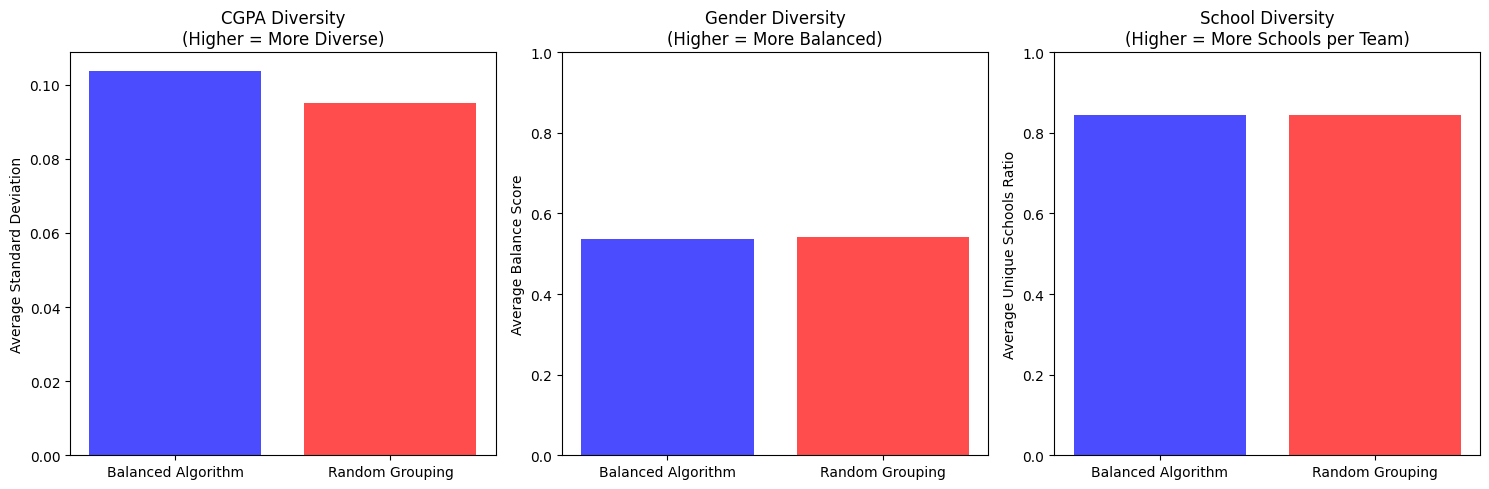


Balanced Algorithm Results:
  Teams evaluated: 1200
  Average CGPA diversity: 0.104
  Average gender balance: 0.536
  Average school diversity: 0.845

Random Grouping Results:
  Teams evaluated: 1200
  Average CGPA diversity: 0.095
  Average gender balance: 0.540
  Average school diversity: 0.844

Gender balance improvement: -0.4%
School diversity improvement: 0.1%


In [9]:
# Simple Algorithm Evaluation System
import matplotlib.pyplot as plt
import random

def calculate_cgpa_diversity(team):
    """Calculate CGPA diversity using standard deviation"""
    cgpas = [float(student['CGPA']) for student in team]
    if len(cgpas) <= 1:
        return 0
    
    # Calculate mean
    mean = sum(cgpas) / len(cgpas)
    
    # Calculate standard deviation
    variance = sum((x - mean) ** 2 for x in cgpas) / len(cgpas)
    std_dev = variance ** 0.5
    
    return std_dev

def calculate_gender_diversity(team):
    """Calculate gender diversity with aggressive penalties for imbalance"""
    genders = [student['Gender'] for student in team]
    male_count = genders.count('Male')
    female_count = genders.count('Female')
    total = len(genders)
    
    if total == 0:
        return 0
    
    # If only one gender, diversity is 0
    if male_count == 0 or female_count == 0:
        return 0
    
    # Calculate balance ratio
    male_ratio = male_count / total
    
    # Calculate distance from perfect balance
    balance_distance = abs(male_ratio - 0.5)
    
    # Use exponential penalty for imbalance (squares the penalty)
    diversity_score = (1 - balance_distance) ** 2
    
    # Heavy penalties for token representation and poor balance
    min_gender_count = min(male_count, female_count)
    
    if min_gender_count == 1:
        # Token representation: very heavy penalty
        if total >= 5:
            diversity_score *= 0.2  # 80% penalty for 5+ person teams
        elif total == 4:
            diversity_score *= 0.3  # 70% penalty for 4 person teams
        else:
            diversity_score *= 0.5  # 50% penalty for smaller teams
    
    elif min_gender_count == 2 and total >= 6:
        # Still quite unbalanced for larger teams
        diversity_score *= 0.6  # 40% penalty
    
    return diversity_score

def calculate_school_diversity(team):
    """Calculate school diversity (number of unique schools / team size)"""
    schools = [student['School'] for student in team]
    unique_schools = len(set(schools))
    total_students = len(schools)
    
    if total_students == 0:
        return 0
    
    return unique_schools / total_students

def create_random_teams(students, team_size):
    """Create random teams for comparison"""
    shuffled_students = students.copy()
    random.shuffle(shuffled_students)
    
    teams = []
    for i in range(0, len(shuffled_students), team_size):
        team = shuffled_students[i:i + team_size]
        if len(team) >= 2:  # Only include teams with at least 2 members
            teams.append(team)
    
    return teams

def evaluate_algorithm_effectiveness():
    """Evaluate and visualize algorithm effectiveness"""
    print("\n=== Algorithm Effectiveness Evaluation ===")
    
    # Read the generated team data
    balanced_teams = {}
    
    # Group students by their assigned teams
    for student_data in team_data:
        team_id = student_data['Team Assigned']
        if team_id not in balanced_teams:
            balanced_teams[team_id] = []
        balanced_teams[team_id].append(student_data)
    
    # Calculate diversity metrics for balanced teams
    balanced_cgpa_diversity = []
    balanced_gender_diversity = []
    balanced_school_diversity = []
    
    for team in balanced_teams.values():
        if len(team) >= 2:  # Only evaluate teams with at least 2 members
            balanced_cgpa_diversity.append(calculate_cgpa_diversity(team))
            balanced_gender_diversity.append(calculate_gender_diversity(team))
            balanced_school_diversity.append(calculate_school_diversity(team))
    
    # Create random teams for comparison
    all_students = list(team_data)
    random_teams = create_random_teams(all_students, 5)  # Assuming team size of 5
    
    # Calculate diversity metrics for random teams
    random_cgpa_diversity = []
    random_gender_diversity = []
    random_school_diversity = []
    
    for team in random_teams:
        random_cgpa_diversity.append(calculate_cgpa_diversity(team))
        random_gender_diversity.append(calculate_gender_diversity(team))
        random_school_diversity.append(calculate_school_diversity(team))
    
    # Create simple visualizations
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # CGPA Diversity Comparison
    axes[0].bar(['Balanced Algorithm', 'Random Grouping'], 
                [sum(balanced_cgpa_diversity)/len(balanced_cgpa_diversity) if balanced_cgpa_diversity else 0,
                 sum(random_cgpa_diversity)/len(random_cgpa_diversity) if random_cgpa_diversity else 0],
                color=['blue', 'red'], alpha=0.7)
    axes[0].set_title('CGPA Diversity\n(Higher = More Diverse)')
    axes[0].set_ylabel('Average Standard Deviation')
    
    # Gender Diversity Comparison
    axes[1].bar(['Balanced Algorithm', 'Random Grouping'], 
                [sum(balanced_gender_diversity)/len(balanced_gender_diversity) if balanced_gender_diversity else 0,
                 sum(random_gender_diversity)/len(random_gender_diversity) if random_gender_diversity else 0],
                color=['blue', 'red'], alpha=0.7)
    axes[1].set_title('Gender Diversity\n(Higher = More Balanced)')
    axes[1].set_ylabel('Average Balance Score')
    axes[1].set_ylim(0, 1)
    
    # School Diversity Comparison
    axes[2].bar(['Balanced Algorithm', 'Random Grouping'], 
                [sum(balanced_school_diversity)/len(balanced_school_diversity) if balanced_school_diversity else 0,
                 sum(random_school_diversity)/len(random_school_diversity) if random_school_diversity else 0],
                color=['blue', 'red'], alpha=0.7)
    axes[2].set_title('School Diversity\n(Higher = More Schools per Team)')
    axes[2].set_ylabel('Average Unique Schools Ratio')
    axes[2].set_ylim(0, 1)
    
    plt.tight_layout()
    plt.savefig('algorithm_effectiveness_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Print summary statistics
    print(f"\nBalanced Algorithm Results:")
    print(f"  Teams evaluated: {len(balanced_teams)}")
    print(f"  Average CGPA diversity: {sum(balanced_cgpa_diversity)/len(balanced_cgpa_diversity):.3f}" if balanced_cgpa_diversity else "  No CGPA diversity data")
    print(f"  Average gender balance: {sum(balanced_gender_diversity)/len(balanced_gender_diversity):.3f}" if balanced_gender_diversity else "  No gender diversity data")
    print(f"  Average school diversity: {sum(balanced_school_diversity)/len(balanced_school_diversity):.3f}" if balanced_school_diversity else "  No school diversity data")
    
    print(f"\nRandom Grouping Results:")
    print(f"  Teams evaluated: {len(random_teams)}")
    print(f"  Average CGPA diversity: {sum(random_cgpa_diversity)/len(random_cgpa_diversity):.3f}" if random_cgpa_diversity else "  No CGPA diversity data")
    print(f"  Average gender balance: {sum(random_gender_diversity)/len(random_gender_diversity):.3f}" if random_gender_diversity else "  No gender diversity data")
    print(f"  Average school diversity: {sum(random_school_diversity)/len(random_school_diversity):.3f}" if random_school_diversity else "  No school diversity data")
    
    # Calculate improvement percentages
    if balanced_gender_diversity and random_gender_diversity:
        gender_improvement = ((sum(balanced_gender_diversity)/len(balanced_gender_diversity)) - 
                             (sum(random_gender_diversity)/len(random_gender_diversity))) * 100
        print(f"\nGender balance improvement: {gender_improvement:.1f}%")
    
    if balanced_school_diversity and random_school_diversity:
        school_improvement = ((sum(balanced_school_diversity)/len(balanced_school_diversity)) - 
                             (sum(random_school_diversity)/len(random_school_diversity))) * 100
        print(f"School diversity improvement: {school_improvement:.1f}%")

# Run the evaluation
evaluate_algorithm_effectiveness()